# Домашнее задание №1

**Задачи**:
1. Найти датасет
2. Обучить как минимум 2 разных архитектуры сетей
3. Обучить сети, используя техники:
    - Итеративная аугментация
    - Итеративная разморозка слоев с адаптивным lr
    - Псевдолейблинг
4. Сравнить результаты

## Описание датасета и моделей



### **Датасет Caltech-256**:
- 30 607 изображений в исходном наборе: животные, транспорт, электроника, еда, одежда, растения и т.д.
- 256 классов + 1 дополнительный класс «clutter» (фоновый мусор); все 827 изображений clutter удалены
- После удаления clutter используется 29 780 изображений
- Классы несбалансированы; от 80 до более чем 800 изображений на класс

### **Модели**:

1. **MobileNetV3-Small** — компактная сверточная сеть с блоками inverted residual и SE-модулями; около 2.5 млн параметров.
2. **ShuffleNetV2 x1.0** — эффективная сверточная сеть с channel shuffle; около 2.3 млн параметров.

Обе модели предобучены на ImageNet, классификационный слой заменяется на новый с 256 выходами. Такие архитектуры выбраны, так как они легкие и быстрые для обучения на CPU.

## Подготовка датасета

In [35]:
# Autoreload external python modules
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [36]:
import os
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from IPython.display import display

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "src").is_dir():
    PROJECT_DIR = PROJECT_DIR / "hw1"
sys.path.insert(0, str(PROJECT_DIR))

from src.data import (
    build_datasets,
    load_or_create_splits,
    load_preprocessed_data,
    preprocess_caltech256,
)
from src.experiments import (
    AugmentationStage,
    BaselineConfig,
    ModelSettings,
    UnfreezeStage,
    build_comparison_table,
    load_experiment_result,
    run_baseline_experiment,
    run_unfreeze_experiment,
)
from src.utils import configure_runtime, set_seed

In [37]:
SEED = 42
IMAGE_SIZE = 160

DATA_DIR = PROJECT_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "256_ObjectCategories"
PREPROCESSED_DIR = DATA_DIR / "preprocessed"
CHECKPOINT_DIR = DATA_DIR / "checkpoints"
IMAGES_PATH = PREPROCESSED_DIR / "images.npy"
LABELS_PATH = PREPROCESSED_DIR / "labels.npy"
SPLITS_PATH = PREPROCESSED_DIR / "splits.npz"

TRAIN_FRACTION = 0.7
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15

# Runtime settings
NUM_CLASSES = 256
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_THREADS = os.cpu_count() or 1
NUM_WORKERS = 0

# Training settings
BACKBONE_LR = 1e-4
CLASSIFIER_LR = 1e-3
WEIGHT_DECAY = 1e-4
BASELINE_PREFIX = "baseline_local"

# The baseline is already trained: reuse its checkpoints instead of
# retraining. Set to True only for a full rerun.
RETRAIN_BASELINE = False

# Baseline settings
MODEL_SETTINGS = {
    "mobilenet_v3_small": ModelSettings(
        batch_size=64,
        channels_last=True,
        epochs=10,
        early_stopping_patience=3,
    ),
    "shufflenet_v2_x1_0": ModelSettings(
        batch_size=64,
        channels_last=True,
        epochs=10,
        early_stopping_patience=3,
    ),
}

# Augmentation settings
# 3+3+4 = 10 epochs, as in the baseline
AUG_STAGES = [
    AugmentationStage(level=0, epochs=3),
    AugmentationStage(level=1, epochs=3),
    AugmentationStage(level=2, epochs=4),
]

# Unfreezing settings
# 2+3+3+2 = 10 epochs, as in the baseline
UNFREEZE_STAGES = [
    UnfreezeStage(group="head", epochs=2),  # lr 1e-3
    UnfreezeStage(group="late", epochs=3),  # lr 1e-4
    UnfreezeStage(group="mid", epochs=3),  # lr 1e-5
    UnfreezeStage(group="early", epochs=2),  # lr 1e-6
]

for directory in [DATA_DIR, PREPROCESSED_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
configure_runtime(NUM_THREADS)

print(f"Project directory: {PROJECT_DIR}")
print(f"Device: {DEVICE}")
print(f"CPU threads: {torch.get_num_threads()}")
print(f"Models: {list(MODEL_SETTINGS)}")

Project directory: d:\repos\applied-ml\hw1
Device: cpu
CPU threads: 8
Models: ['mobilenet_v3_small', 'shufflenet_v2_x1_0']


In [38]:
preprocess_caltech256(
    raw_dir=RAW_DATA_DIR,
    output_dir=PREPROCESSED_DIR,
    image_size=IMAGE_SIZE,
)

Preprocessed arrays already exist: d:\repos\applied-ml\hw1\data\preprocessed


(WindowsPath('d:/repos/applied-ml/hw1/data/preprocessed/images.npy'),
 WindowsPath('d:/repos/applied-ml/hw1/data/preprocessed/labels.npy'))

In [39]:
images, labels = load_preprocessed_data(
    IMAGES_PATH,
    LABELS_PATH,
)

print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
print("Unique labels:", len(np.unique(labels)))
print("Image and label counts match:", len(images) == len(labels))

Images: (29780, 160, 160, 3) uint8
Labels: (29780,) int64
Unique labels: 256
Image and label counts match: True


In [40]:
train_indices, val_indices, test_indices = load_or_create_splits(
    labels=labels,
    splits_path=SPLITS_PATH,
    seed=SEED,
    train_fraction=TRAIN_FRACTION,
    val_fraction=VAL_FRACTION,
    test_fraction=TEST_FRACTION,
)

print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Test:", len(test_indices))

Train: 20845
Validation: 4467
Test: 4468


In [41]:
train_dataset, val_dataset, test_dataset = build_datasets(
    images_path=IMAGES_PATH,
    labels_path=LABELS_PATH,
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices,
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 20845
Validation dataset: 4467
Test dataset: 4468


## Бейзлайн

Бейзлайн уже обучен. По умолчанию результаты загружаются из сохранённых
чекпоинтов (`RETRAIN_BASELINE = False`), поэтому повторное обучение не
запускается. Для полного перезапуска установите `RETRAIN_BASELINE = True`.

In [42]:
baseline_results = {}
criterion = nn.CrossEntropyLoss()

mobilenet_name = "mobilenet_v3_small"
shufflenet_name = "shufflenet_v2_x1_0"

baseline_config = BaselineConfig(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    test_dataset=test_dataset,
    criterion=criterion,
    checkpoint_dir=CHECKPOINT_DIR,
    device=DEVICE,
    seed=SEED,
    num_classes=NUM_CLASSES,
    num_workers=NUM_WORKERS,
    backbone_lr=BACKBONE_LR,
    classifier_lr=CLASSIFIER_LR,
    weight_decay=WEIGHT_DECAY,
    baseline_prefix=BASELINE_PREFIX,
)

In [43]:
if RETRAIN_BASELINE:
    baseline_results[mobilenet_name] = run_baseline_experiment(
        model_name=mobilenet_name,
        settings=MODEL_SETTINGS[mobilenet_name],
        config=baseline_config,
    )
else:
    baseline_results[mobilenet_name] = load_experiment_result(
        model_name=mobilenet_name,
        settings=MODEL_SETTINGS[mobilenet_name],
        config=baseline_config,
        experiment_name=f"{BASELINE_PREFIX}_{mobilenet_name}",
    )

Loaded checkpoint from epoch 4


In [ ]:
if RETRAIN_BASELINE:
    baseline_results[shufflenet_name] = run_baseline_experiment(
        model_name=shufflenet_name,
        settings=MODEL_SETTINGS[shufflenet_name],
        config=baseline_config,
    )
else:
    baseline_results[shufflenet_name] = load_experiment_result(
        model_name=shufflenet_name,
        settings=MODEL_SETTINGS[shufflenet_name],
        config=baseline_config,
        experiment_name=f"{BASELINE_PREFIX}_{shufflenet_name}",
    )

Loaded checkpoint from epoch 8


In [ ]:
baseline_comparison = build_comparison_table(baseline_results)
comparison_path = CHECKPOINT_DIR / "baseline_comparison.csv"
baseline_comparison.to_csv(comparison_path)

print(f"Saved comparison table to {comparison_path}")

display(
    baseline_comparison.sort_values(
        by="val_macro_f1",
        ascending=False,
    )
)

Saved comparison table to d:\repos\applied-ml\hw1\data\checkpoints\baseline_comparison.csv


,val_loss,val_accuracy,val_macro_f1,val_weighted_f1,test_loss,test_accuracy,test_macro_f1,test_weighted_f1,train_minutes,epochs_run
Model,,,,,,,,,,
shufflenet_v2_x1_0,1.141420,0.719051,0.695798,0.717463,1.192040,0.714637,0.691546,0.712125,89.695192,10.0
mobilenet_v3_small,1.285354,0.706067,0.685663,0.707451,1.295513,0.704790,0.684898,0.706195,38.406336,7.0


## Итеративная аугментация

Расписание: уровни 0 → 1 → 2 за 3 + 3 + 4 = 10 эпох — тот же максимальный
бюджет, что у бейзлайна. Patience early stopping (3) перезапускается на
каждом уровне: смена силы аугментации — это новый режим обучения, и стадия
не должна начинаться с уже исчерпанным счётчиком.

In [ ]:
iter_aug_results = {}


mobilenet_v3_small: batch_size=64, channels_last=True, epochs=10, train batches=326

Augmentation stage 1/3: level=0, epochs=3

Epoch [1/3] (global epoch 1)
Train | Loss: 2.2303 | Accuracy: 0.5126 | Macro F1: 0.4813 | Weighted F1: 0.5017
Val   | Loss: 1.3181 | Accuracy: 0.6819 | Macro F1: 0.6506 | Weighted F1: 0.6742
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6506

Epoch [2/3] (global epoch 2)
Train | Loss: 0.9578 | Accuracy: 0.7528 | Macro F1: 0.7353 | Weighted F1: 0.7506
Val   | Loss: 1.2333 | Accuracy: 0.6971 | Macro F1: 0.6750 | Weighted F1: 0.6975
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6750

Epoch [3/3] (global epoch 3)
Train | Loss: 0.6202 | Accuracy: 0.8314 | Macro F1: 0.8207 | Weighted F1: 0.8305
Val   | Loss: 1.2351 | Accuracy: 0.7009 | Macro F1: 0.6770 | Weighted F1: 0.6990
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6770

Training finished
Best Val Macro F1: 0.6770
Be

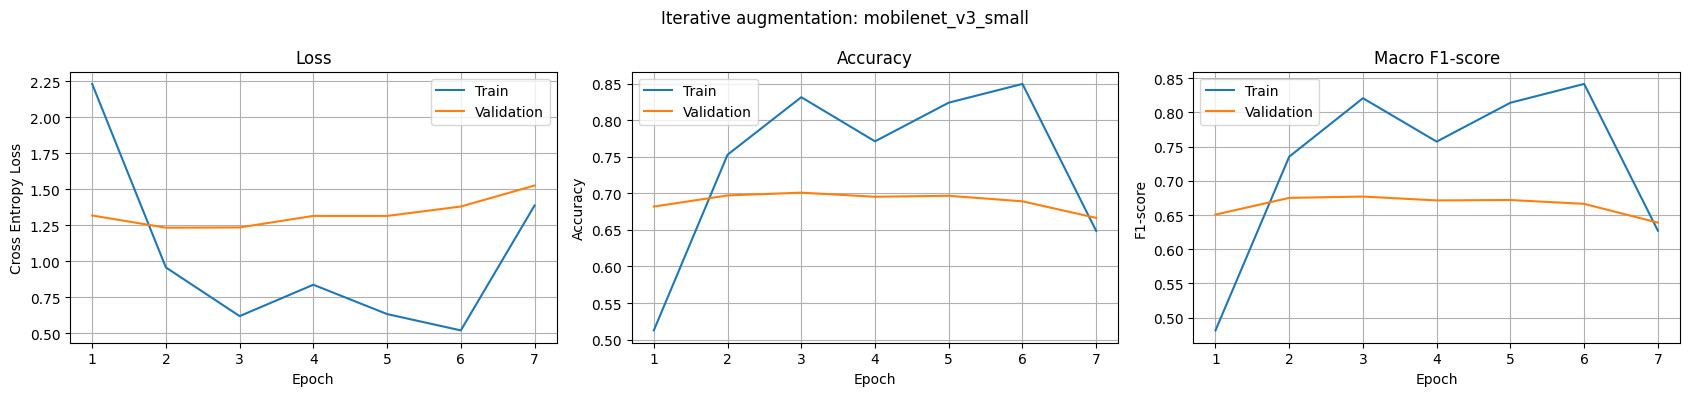

In [ ]:
iter_aug_results[mobilenet_name] = run_baseline_experiment(
    model_name=mobilenet_name,
    settings=MODEL_SETTINGS[mobilenet_name],
    config=baseline_config,
    aug_stages=AUG_STAGES,
    experiment_prefix="iter_aug_local",
    title_prefix="Iterative augmentation",
)

In [ ]:
# if there will be an error
iter_aug_results

{'mobilenet_v3_small': ExperimentResult(model_name='mobilenet_v3_small', model=MobileNetV3(
   (features): Sequential(
     (0): Conv2dNormActivation(
       (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
       (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
       (2): Hardswish()
     )
     (1): InvertedResidual(
       (block): Sequential(
         (0): Conv2dNormActivation(
           (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
           (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
           (2): ReLU(inplace=True)
         )
         (1): SqueezeExcitation(
           (avgpool): AdaptiveAvgPool2d(output_size=1)
           (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
           (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
           (activation): ReLU()
           (scale_activation): Hardsigmoid


shufflenet_v2_x1_0: batch_size=64, channels_last=True, epochs=10, train batches=326

Augmentation stage 1/3: level=0, epochs=3

Epoch [1/3] (global epoch 1)
Train | Loss: 4.5000 | Accuracy: 0.1540 | Macro F1: 0.0892 | Weighted F1: 0.1122
Val   | Loss: 3.2361 | Accuracy: 0.3669 | Macro F1: 0.2593 | Weighted F1: 0.2965
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.2593

Epoch [2/3] (global epoch 2)
Train | Loss: 2.4262 | Accuracy: 0.5103 | Macro F1: 0.4525 | Weighted F1: 0.4783
Val   | Loss: 1.8323 | Accuracy: 0.5959 | Macro F1: 0.5430 | Weighted F1: 0.5725
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.5430

Epoch [3/3] (global epoch 3)
Train | Loss: 1.5002 | Accuracy: 0.6736 | Macro F1: 0.6379 | Weighted F1: 0.6604
Val   | Loss: 1.4429 | Accuracy: 0.6624 | Macro F1: 0.6237 | Weighted F1: 0.6505
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6237

Training finished
Best Val Macro F1: 0.6237
Be

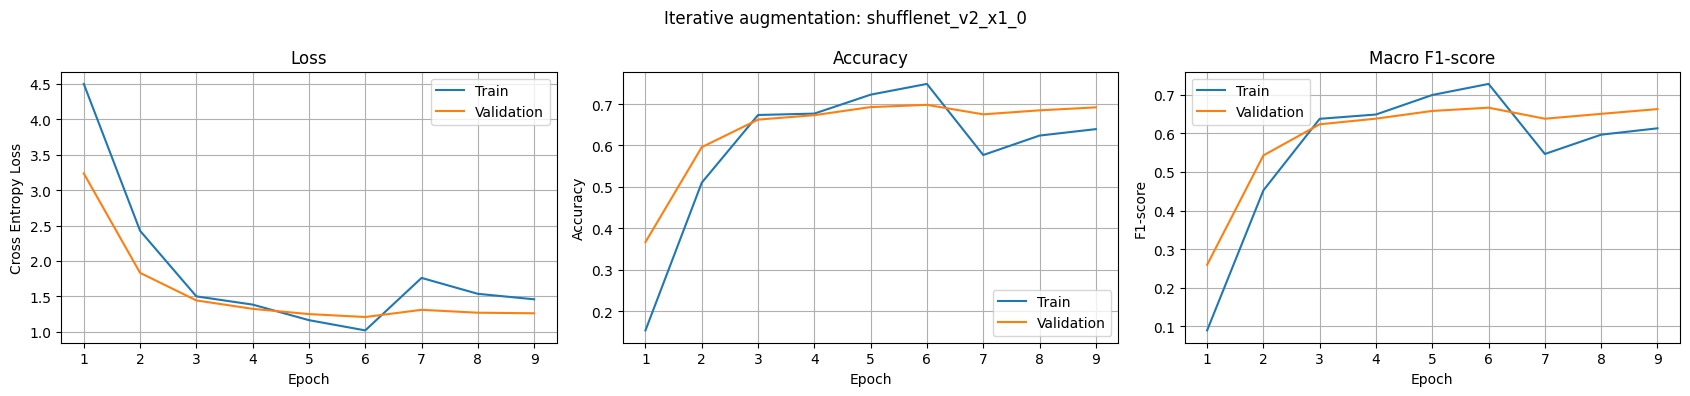

In [ ]:
iter_aug_results[shufflenet_name] = run_baseline_experiment(
    model_name=shufflenet_name,
    settings=MODEL_SETTINGS[shufflenet_name],
    config=baseline_config,
    aug_stages=AUG_STAGES,
    experiment_prefix="iter_aug_local",
    title_prefix="Iterative augmentation",
)

In [ ]:
iter_aug_results

{'mobilenet_v3_small': ExperimentResult(model_name='mobilenet_v3_small', model=MobileNetV3(
   (features): Sequential(
     (0): Conv2dNormActivation(
       (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
       (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
       (2): Hardswish()
     )
     (1): InvertedResidual(
       (block): Sequential(
         (0): Conv2dNormActivation(
           (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
           (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
           (2): ReLU(inplace=True)
         )
         (1): SqueezeExcitation(
           (avgpool): AdaptiveAvgPool2d(output_size=1)
           (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
           (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
           (activation): ReLU()
           (scale_activation): Hardsigmoid

In [ ]:
display(
    build_comparison_table(
        {
            **{f"{k} | baseline": v for k, v in baseline_results.items()},
            **{f"{k} | iter_aug": v for k, v in iter_aug_results.items()},
        }
    )
)

,val_loss,val_accuracy,val_macro_f1,val_weighted_f1,test_loss,test_accuracy,test_macro_f1,test_weighted_f1,train_minutes,epochs_run
Model,,,,,,,,,,
mobilenet_v3_small | iter_aug,1.235104,0.700918,0.676971,0.698994,1.252666,0.697851,0.675995,0.696309,59.097596,7.0
shufflenet_v2_x1_0 | iter_aug,1.208710,0.698008,0.666741,0.690202,1.238576,0.694942,0.666699,0.689772,96.815321,9.0


## Unfreeze

Расписание: head → late → mid → early за 2 + 3 + 3 + 2 = 10 эпох — тот же
максимальный бюджет, что у бейзлайна. Early stopping включён с patience=3
и перезапускается на каждой стадии.

Замороженные BatchNorm-слои остаются в eval(): `requires_grad=False` сам по
себе не останавливает обновление running mean/var, поэтому `run_epoch`
переводит BN-модули без обучаемых параметров в eval. Заморозка становится
строгой, и «замороженный» backbone не меняется.

In [ ]:
unfreeze_results = {}


mobilenet_v3_small: batch_size=64, channels_last=True, stages=[('head', 2), ('late', 3), ('mid', 3), ('early', 2)], total epochs=10 (baseline: 10)

Unfreezing stage 1/4: +head (lr=1e-03), epochs=2, trainable params=853,248

Epoch [1/2] (global epoch 1)
Train | Loss: 2.4008 | Accuracy: 0.4870 | Macro F1: 0.4531 | Weighted F1: 0.4734
Val   | Loss: 1.5160 | Accuracy: 0.6378 | Macro F1: 0.6041 | Weighted F1: 0.6308
head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6041

Epoch [2/2] (global epoch 2)
Train | Loss: 1.2163 | Accuracy: 0.6963 | Macro F1: 0.6756 | Weighted F1: 0.6934
Val   | Loss: 1.4586 | Accuracy: 0.6467 | Macro F1: 0.6204 | Weighted F1: 0.6450
head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6204

Training finished
Best Val Macro F1: 0.6204
Best checkpoint: d:\repos\applied-ml\hw1\data\checkpoints\unfreeze_local_mobilenet_v3_small_best.pt
History: d:\repos\applied-ml\hw1\data\checkpoints\unfreeze_local_mobilenet_v3_small_history.json

Unfreezing stage 2/4: +late (lr

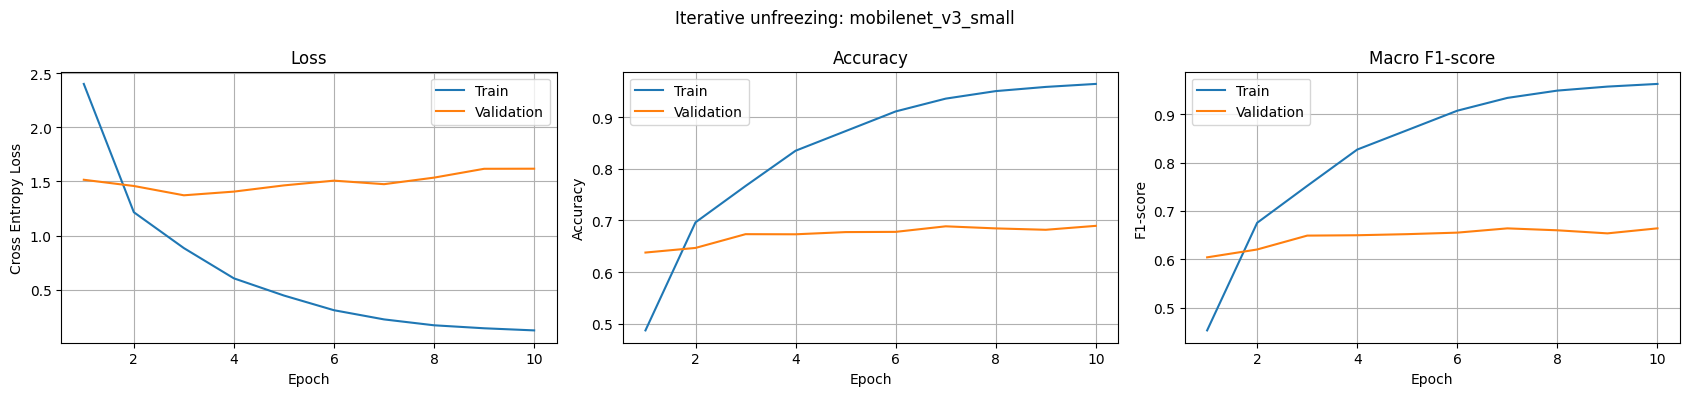

In [ ]:
unfreeze_results[mobilenet_name] = run_unfreeze_experiment(
    model_name=mobilenet_name,
    settings=MODEL_SETTINGS[mobilenet_name],
    config=baseline_config,
    stages=UNFREEZE_STAGES,
    lr_factor=10.0,
    experiment_prefix="unfreeze_local",
)

In [ ]:
unfreeze_results

{'mobilenet_v3_small': ExperimentResult(model_name='mobilenet_v3_small', model=MobileNetV3(
   (features): Sequential(
     (0): Conv2dNormActivation(
       (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
       (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
       (2): Hardswish()
     )
     (1): InvertedResidual(
       (block): Sequential(
         (0): Conv2dNormActivation(
           (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
           (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
           (2): ReLU(inplace=True)
         )
         (1): SqueezeExcitation(
           (avgpool): AdaptiveAvgPool2d(output_size=1)
           (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
           (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
           (activation): ReLU()
           (scale_activation): Hardsigmoid


shufflenet_v2_x1_0: batch_size=64, channels_last=True, stages=[('head', 2), ('late', 3), ('mid', 3), ('early', 2)], total epochs=10 (baseline: 10)

Unfreezing stage 1/4: +head (lr=1e-03), epochs=2, trainable params=262,400

Epoch [1/2] (global epoch 1)
Train | Loss: 5.1381 | Accuracy: 0.0556 | Macro F1: 0.0068 | Weighted F1: 0.0242
Val   | Loss: 4.7795 | Accuracy: 0.0963 | Macro F1: 0.0233 | Weighted F1: 0.0505
head LR: 1.00e-03
Best model updated. Val Macro F1: 0.0233

Epoch [2/2] (global epoch 2)
Train | Loss: 4.4972 | Accuracy: 0.1615 | Macro F1: 0.0950 | Weighted F1: 0.1252
Val   | Loss: 4.2223 | Accuracy: 0.2518 | Macro F1: 0.1868 | Weighted F1: 0.2134
head LR: 1.00e-03
Best model updated. Val Macro F1: 0.1868

Training finished
Best Val Macro F1: 0.1868
Best checkpoint: d:\repos\applied-ml\hw1\data\checkpoints\unfreeze_local_shufflenet_v2_x1_0_best.pt
History: d:\repos\applied-ml\hw1\data\checkpoints\unfreeze_local_shufflenet_v2_x1_0_history.json

Unfreezing stage 2/4: +late (lr

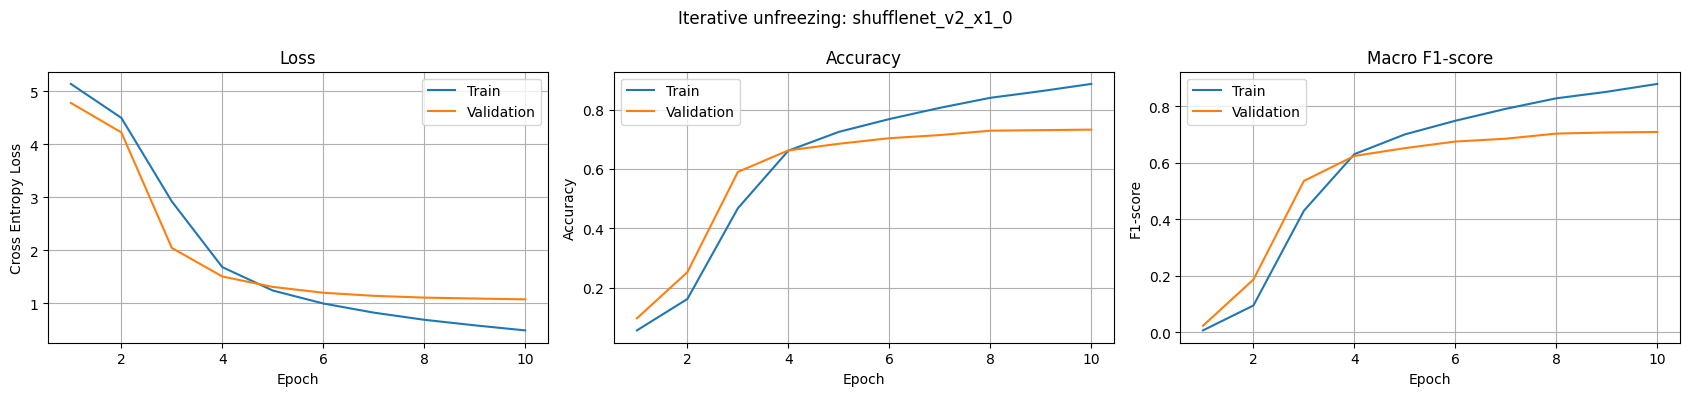

In [ ]:
unfreeze_results[shufflenet_name] = run_unfreeze_experiment(
    model_name=shufflenet_name,
    settings=MODEL_SETTINGS[shufflenet_name],
    config=baseline_config,
    stages=UNFREEZE_STAGES,
    lr_factor=10.0,
    experiment_prefix="unfreeze_local",
)

In [ ]:
unfreeze_results

{'mobilenet_v3_small': ExperimentResult(model_name='mobilenet_v3_small', model=MobileNetV3(
   (features): Sequential(
     (0): Conv2dNormActivation(
       (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
       (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
       (2): Hardswish()
     )
     (1): InvertedResidual(
       (block): Sequential(
         (0): Conv2dNormActivation(
           (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
           (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
           (2): ReLU(inplace=True)
         )
         (1): SqueezeExcitation(
           (avgpool): AdaptiveAvgPool2d(output_size=1)
           (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
           (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
           (activation): ReLU()
           (scale_activation): Hardsigmoid

In [ ]:
display(
    build_comparison_table(
        {
            **{f"{k} | baseline": v for k, v in baseline_results.items()},
            **{f"{k} | iter_aug": v for k, v in iter_aug_results.items()},
            **{f"{k} | unfreeze": v for k, v in unfreeze_results.items()},
        }
    )
)

,val_loss,val_accuracy,val_macro_f1,val_weighted_f1,test_loss,test_accuracy,test_macro_f1,test_weighted_f1,train_minutes,epochs_run
Model,,,,,,,,,,
mobilenet_v3_small | iter_aug,1.235104,0.700918,0.676971,0.698994,1.252666,0.697851,0.675995,0.696309,59.097596,7.0
shufflenet_v2_x1_0 | iter_aug,1.208710,0.698008,0.666741,0.690202,1.238576,0.694942,0.666699,0.689772,96.815321,9.0
mobilenet_v3_small | unfreeze,1.618081,0.689501,0.664085,0.686076,1.635243,0.684646,0.660270,0.681400,36.920817,10.0
shufflenet_v2_x1_0 | unfreeze,1.071391,0.732259,0.709513,0.728629,1.113634,0.723366,0.698489,0.719820,56.120325,10.0
